In [9]:
%cd '/home/mojtaba.kananisarche/'

from Zh.src.utils.load_data import load_data
import numpy as np
import pandas as pd
from typing import List, Optional, Tuple, Optional
from Zh.src.utils.file_folder import create_folders
import os
import json
import pandas as pd
import dataframe_image as dfi
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error
import matplotlib.pyplot as plt
from Zh.src.utils.common import flatten, order_dict_by_key_list, matches_pattern

/home/mojtaba.kananisarche


In [ ]:
def table_results(
results_directory_path : str,
output_directory_path  : Optional[str] = None,
output_file_path_prefix: Optional[str] = 'results',
cmap                   : Optional[str] = "Blues",
reverse_cmap           : Optional[bool] = False,
header_1_bg_color      : Optional[str] = 'silver',
header_1_text_color    : Optional[str] = 'black',
header_2_bg_color      : Optional[str] = 'darkgrey',
header_2_text_color    : Optional[str] = 'black',
maximum_tries          : Optional[int] = 1,
slice_or_video         : Optional[str] = 'slice', #slice, video
video_voting_method    : Optional[str] = 'average', #majority, class_average, average
height                 : Optional[int] = 2,
width                  : Optional[int] = 5,
)->None: 
    
    KEYS_TO_COLLECT       = ['split_info', 'evaluation']

    COLORS                = ['Accent','Blues','BrBG','BuGn','BuPu','CMRmap','Dark2','GnBu','Greens',
                             'Greys','OrRd','Oranges','PRGn','Paired','Pastel1','Pastel2','PiYG',
                             'PuBuGn','PuBu','PuOr','PuRd','Purples','RdBu','RdGy','RdPu','RdYlBu',
                             'RdYlGn','Reds','Set1','Set2','Set3','Spectral','Wistia','YlGnBu','YlGn',
                             'YlOrBr','YlOrRd','afmhot','autumn','binary','bone','brg','bwr','cividis',
                             'cool','coolwarm','copper','cubehelix','flag','gist_earth','gist_gray',
                             'gist_heat','gist_ncar','gist','gist_rainbow','gist_stern','gist_yarg',
                             'gnuplot2','gnuplot','gray','hot','hsv','inferno','jet','magma','nipy_spectral'
                             ,'ocean','pink','plasma','prism','rainbow','seismic','spring','summer','tab10',
                             'tab20','tab20b','tab20c','terrain','turbo','twilight','twilight_shifted','viridis','winter']

    output_directory_path = output_directory_path or results_directory_path
    create_folders(output_directory_path)
    output_file_name = None

    i = 0
    while output_file_name is None:
        i += 1
        if not os.path.exists(os.path.join(output_directory_path, f"{output_file_path_prefix}_{i}.png")):
            output_file_name = f"{output_file_path_prefix}_{i}.png"
    
    output_file_path = os.path.join(output_directory_path, output_file_name)

    data = []
    for file_name in os.listdir(results_directory_path):
        if file_name.endswith('.json'):
            file_path = os.path.join(results_directory_path, file_name)
            with open(file=file_path, mode='r') as json_file:
                j = json.load(json_file)
                try:
                    data.append(
                        {
                            k:v for k, v in j.items() if k in KEYS_TO_COLLECT
                        }
                    )
                except KeyError as e:
                    print("Unable")
                    continue


    data = pd.DataFrame(data = data).dropna(how='all')

    folded_by_column = list(data['split_info'].iloc[0]['test'].keys())[0]

    data.index = data['split_info'].apply(lambda x: x['index']).astype(int).tolist()
    data       = data.sort_index()

    data['split_info_train'] = data['split_info'].apply(lambda x: x['train'][folded_by_column])
    data['split_info_val']   = data['split_info'].apply(lambda x: x['val'][folded_by_column])
    data['split_info_test']  = data['split_info'].apply(lambda x: x['test'][folded_by_column])

    data['evaluation_train'] = data['evaluation'].apply(lambda x: x['train']['metrics'][slice_or_video])
    data['evaluation_val']   = data['evaluation'].apply(lambda x: x['val']['metrics'][slice_or_video])
    data['evaluation_test']  = data['evaluation'].apply(lambda x: x['test']['metrics'][slice_or_video])

    if slice_or_video == 'video':
        data['evaluation_train'] = data['evaluation_train'].apply(lambda x: x[video_voting_method])
        data['evaluation_val']   = data['evaluation_val'].apply(lambda x: x[video_voting_method])
        data['evaluation_test']  = data['evaluation_test'].apply(lambda x: x[video_voting_method])
        
    data['evaluation_train_accuracy'] = data['evaluation_train'].apply(lambda x: x['accuracy'])
    data['evaluation_val_accuracy']   = data['evaluation_val'].apply(lambda x: x['accuracy'])
    data['evaluation_test_accuracy']  = data['evaluation_test'].apply(lambda x: x['accuracy'])

    data['evaluation_train_mae'] = data['evaluation_train'].apply(lambda x: x['mae'])
    data['evaluation_val_mae']   = data['evaluation_val'].apply(lambda x: x['mae'])
    data['evaluation_test_mae']  = data['evaluation_test'].apply(lambda x: x['mae'])

    printable_data = data[['split_info_test', 'split_info_val', 
                           'evaluation_train_mae', 'evaluation_val_mae', 'evaluation_test_mae', 
                           'evaluation_train_accuracy', 'evaluation_val_accuracy', 'evaluation_test_accuracy']].copy()

    multi_index = pd.MultiIndex.from_tuples([
    (f'Split ({folded_by_column})', 'Test'),
    (f'Split ({folded_by_column})', 'Validation'),
    ('MAE', 'Train'),
    ('MAE', 'Validation'),
    ('MAE', 'Test'),
    ('Accuracy', 'Train'),
    ('Accuracy', 'Validation'),
    ('Accuracy', 'Test'),
    ])
    printable_data.columns = multi_index
    printable_data.columns.names = [None, 'Index']

    avg = printable_data.mean(numeric_only=True)
    printable_data.loc['Average'] = avg
    printable_data = printable_data.fillna('-')
    
    cmaps = [f"{cmap}_r", cmap] if reverse_cmap else [cmap, f"{cmap}_r"]

    data_styled = printable_data.style.background_gradient(subset=[('Accuracy', 'Train'), 
                                                         ('Accuracy', 'Validation'), 
                                                         ('Accuracy', 'Test')], axis=None, vmin=0, vmax=1, cmap=cmaps[0]) \
                                      .format(precision=3) \
                                      .background_gradient(subset=[('MAE', 'Train'), 
                                                     ('MAE', 'Validation'), 
                                                     ('MAE', 'Test')], vmin=0, vmax=1, axis=None, cmap=cmaps[1]) \
                                      .set_table_styles(
                                          [
                                              {'selector': 'th','props': [('text-align', 'center'), ('height', f'{height}em'), ('width', f'{width}em')]},
                                              {'selector': 'td','props': [('text-align', 'center'), ('height', f'{height}em'), ('width', f'{width}em')]},
                                              {'selector': 'thead tr:nth-child(1) th:nth-child(1)','props': [('background-color', 'white')]},
                                              {'selector': 'thead tr:nth-child(1)','props': [('background-color', header_1_bg_color), ('color', header_1_text_color)]},
                                              {'selector': 'thead tr:nth-child(2)','props': [('background-color', header_2_bg_color), ('color', header_2_text_color)]},
                                              
                                                #header row 1 vertical line
                                              {'selector': 'thead tr:nth-child(1) th:nth-child(1)', 'props': [('border-right', '15px solid white')]},
                                              {'selector': 'thead tr:nth-child(1) th:nth-child(2)', 'props': [('border-right', '15px solid white')]},
                                              {'selector': 'thead tr:nth-child(1) th:nth-child(3)', 'props': [('border-right', '15px solid white')]},
                                                #header row 2 vertical line
                                              {'selector': 'thead tr:nth-child(2) th:nth-child(1)', 'props': [('border-right', '15px solid white')]},
                                              {'selector': 'thead tr:nth-child(2) th:nth-child(3)', 'props': [('border-right', '15px solid white')]},
                                              {'selector': 'thead tr:nth-child(2) th:nth-child(6)', 'props': [('border-right', '15px solid white')]},
                                                #body vertical line
                                              {'selector': 'tbody th:nth-child(1)', 'props': [('border-right', '15px solid white')]},
                                              {'selector': 'tbody td:nth-child(3)', 'props': [('border-right', '15px solid white')]},
                                              {'selector': 'tbody td:nth-child(6)', 'props': [('border-right', '15px solid white')]},
                                                #Bottom line
                                              {'selector': f'tbody tr:nth-child({printable_data.shape[0]})', 'props': [('border-top', '3px solid SpringGreen')]},
                                              {'selector': f'tbody tr:nth-child({printable_data.shape[0]})', 'props': [('border-bottom', '3px solid SpringGreen')]},
                                              {'selector': f'tbody tr:nth-child({printable_data.shape[0]})', 'props': [('font-weight', 'bold')]},
                                          ]
                                      )

    for attempt in range(maximum_tries):
        try:
            data_styled.export_png(filename=output_file_path, table_conversion='selenium')
            print(f"Try Number {attempt} Succeeded.")
            break
        except:
            print(f"Try Number {attempt} Failed.")

    return data_styled

In [328]:
data =table_results(
results_directory_path  = '/home/mojtaba.kananisarche/Zh/outputs/2025-04-20|06:42:10|RNN_FACENET_5CV',
output_directory_path   = None,
output_file_path_prefix = 'results',
cmap                    = "Blues",
reverse_cmap            = False,
header_1_bg_color       = 'silver',
header_1_text_color     = 'black',
header_2_bg_color       = 'darkgrey',
header_2_text_color     = 'black',
maximum_tries           = 1,
slice_or_video          = 'slice', #slice, video
video_voting_method     = 'average', #majority, class_average, average
height                  = 2,
width                   = 5,
)
data

Try Number 0 Succeeded.


In [317]:
data = table_results(
    '/home/mojtaba.kananisarche/Zh/outputs/2025-04-20|06:42:10|RNN_FACENET_5CV',
    slice_or_video='video',
    video_voting_method='class_average',
    height = 2,
    width=5,
    maximum_tries=0,
)
data

In [243]:
data = table_results(
    '/home/mojtaba.kananisarche/Zh/outputs/2025-04-20|06:42:10|RNN_FACENET_5CV',
    slice_or_video='video',
    video_voting_method='class_average',
    height = 2,
    width=2
)
data

In [136]:
data[['split_info_test', 'split_info_val', 
      'evaluation_train_mae', 'evaluation_test_mae', 'evaluation_val_mae', 
      'evaluation_train_accuracy', 'evaluation_test_accuracy', 'evaluation_val_accuracy']]

,split_info_test,split_info_val,evaluation_train_mae,evaluation_test_mae,evaluation_val_mae,evaluation_train_accuracy,evaluation_test_accuracy,evaluation_val_accuracy
5,[2],[5],1.500,0.0,0.0,0.666667,1.0,1.0
7,[4],[2],1.125,0.0,0.0,0.750000,1.0,1.0


In [130]:
data['evaluation_train'].apply(lambda x: x['accuracy'])

5    0.666667
7    0.750000
Name: evaluation_train, dtype: float64

In [121]:
data['evaluation_train'][5]

{'2.0': {'precision': 0.6666666666666666,
  'recall': 1.0,
  'f1-score': 0.8,
  'mae': 0.0,
  'support': 2.0},
 '6.5': {'precision': 0.0,
  'recall': 0.0,
  'f1-score': 0.0,
  'mae': 4.5,
  'support': 1.0},
 '8.5': {'precision': 0.0,
  'recall': 0.0,
  'f1-score': 0.0,
  'mae': 0.0,
  'support': 0.0},
 'accuracy': 0.6666666666666666,
 'macro avg': {'precision': 0.2222222222222222,
  'recall': 0.3333333333333333,
  'f1-score': 0.26666666666666666,
  'support': 3.0},
 'weighted avg': {'precision': 0.4444444444444444,
  'recall': 0.6666666666666666,
  'f1-score': 0.5333333333333333,
  'support': 3.0},
 'confusion matrix': [[2, 0, 0], [1, 0, 0], [0, 0, 0]]}

In [11]:
data = table_results(
    results_directory_path = '/home/mojtaba.kananisarche/Zh/models/2025-04-15|23:45:55|RNN_FACENET_5CV',
    unique_classes         = [2,6.5,8.5],
    index                  = -1,
    split                  = 'all',
    cmap                   = None,
    corner_bg_color        = 'indianred',
    corner_text_color      = 'black',
    labels_bg_color        = 'beige',
    labels_text_color      = 'black',
    pred_true_bg_color     = 'silver',
    pred_true_text_color   = 'black',
    maximum_tries          = 0
)

split - train
split - test
split - val


In [12]:
data['train']

In [6]:
img = data['val'].export_png('test2.png', table_conversion='selenium', corner='123')

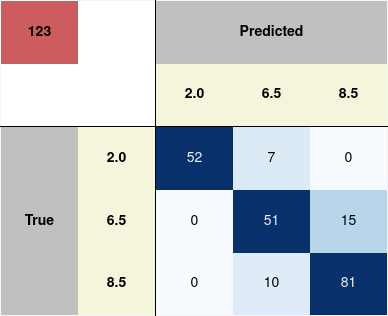

In [7]:
from IPython.display import display, Image
display(Image(data=img))

In [6]:
from PIL import Image
from io import BytesIO

image = Image.open(BytesIO(img))
print(image.size)  # Output will be (width, height)

(388, 316)


In [107]:
dft

In [110]:
await dfi.export_async(obj=dft, filename='test5.png', table_conversion='playwright', corner='Combined<br><br>Validation', timeout=60000)

TimeoutError: Locator.bounding_box: Timeout 30000ms exceeded.
Call log:
  - waiting for locator("#dfi_table table")


In [46]:
await dfi.export_async(obj=dft, filename='test4.png', table_conversion='playwright', corner='Combined<br><br>Train')

In [107]:
data['val']

In [74]:
def flatten(lst):
    flat = []
    for item in lst:
        if isinstance(item, list):
            flat.extend(flatten(item))
        else:
            flat.append(item)
    return flat

In [73]:
flatten(list((data['y_train'])))

[2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0

In [45]:
df1, df2, df3 = await table_results(results_directory_path = '/home/mojtaba.kananisarche/Zh/models/2025-04-15|23:45:55|RNN_FACENET_5CV', unique_classes=[2,6.5,8.5], index=1, height=3, width=3)

In [46]:
df3

In [159]:
b = dfi.export_async(obj=df2, filename='test5.png', table_conversion='playwright', corner='Train')
await b

In [ ]:
kwargs = 



{'exclude_styles': False, 'encoding': 'utf-8', 'doctype_html': False, 'corner': 'test'}

In [11]:
if 'corner' in kwargs.keys():
    print(1)

1


In [9]:
a = {'uuid': 'ecb01', 'table_styles': [], 'caption': None, 'head': [[{'type': 'th', 'value': '&nbsp;', 'class': 'blank', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': '&nbsp;', 'class': 'blank level0', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': 'Predicted', 'class': 'col_heading level0 col0', 'is_visible': True, 'display_value': 'Predicted', 'attributes': 'colspan="3"', 'id': 'level0_col0'}, {'type': 'th', 'value': 'Predicted', 'class': 'col_heading level0 col1', 'is_visible': False, 'display_value': 'Predicted', 'attributes': '', 'id': 'level0_col1'}, {'type': 'th', 'value': 'Predicted', 'class': 'col_heading level0 col2', 'is_visible': False, 'display_value': 'Predicted', 'attributes': '', 'id': 'level0_col2'}], [{'type': 'th', 'value': '&nbsp;', 'class': 'blank', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': '&nbsp;', 'class': 'blank level1', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': '2.0', 'class': 'col_heading level1 col0', 'is_visible': True, 'display_value': '2.0', 'attributes': '', 'id': 'level1_col0'}, {'type': 'th', 'value': '6.5', 'class': 'col_heading level1 col1', 'is_visible': True, 'display_value': '6.5', 'attributes': '', 'id': 'level1_col1'}, {'type': 'th', 'value': '8.5', 'class': 'col_heading level1 col2', 'is_visible': True, 'display_value': '8.5', 'attributes': '', 'id': 'level1_col2'}]], 'index_lengths': {(0, 0): 3, (1, 0): 1, (1, 1): 1, (1, 2): 1}, 'body': [[{'type': 'th', 'value': 'True', 'class': 'row_heading level0 row0', 'is_visible': True, 'display_value': 'True', 'attributes': 'rowspan="3"', 'id': 'level0_row0'}, {'type': 'th', 'value': '2.0', 'class': 'row_heading level1 row0', 'is_visible': True, 'display_value': '2.0', 'attributes': '', 'id': 'level1_row0'}, {'type': 'td', 'value': 233, 'class': 'data row0 col0', 'is_visible': True, 'attributes': '', 'display_value': '233', 'id': 'row0_col0'}, {'type': 'td', 'value': 0, 'class': 'data row0 col1', 'is_visible': True, 'attributes': '', 'display_value': '0', 'id': 'row0_col1'}, {'type': 'td', 'value': 0, 'class': 'data row0 col2', 'is_visible': True, 'attributes': '', 'display_value': '0', 'id': 'row0_col2'}], [{'type': 'th', 'value': 'True', 'class': 'row_heading level0 row1', 'is_visible': False, 'display_value': 'True', 'attributes': '', 'id': 'level0_row1'}, {'type': 'th', 'value': '6.5', 'class': 'row_heading level1 row1', 'is_visible': True, 'display_value': '6.5', 'attributes': '', 'id': 'level1_row1'}, {'type': 'td', 'value': 0, 'class': 'data row1 col0', 'is_visible': True, 'attributes': '', 'display_value': '0', 'id': 'row1_col0'}, {'type': 'td', 'value': 246, 'class': 'data row1 col1', 'is_visible': True, 'attributes': '', 'display_value': '246', 'id': 'row1_col1'}, {'type': 'td', 'value': 0, 'class': 'data row1 col2', 'is_visible': True, 'attributes': '', 'display_value': '0', 'id': 'row1_col2'}], [{'type': 'th', 'value': 'True', 'class': 'row_heading level0 row2', 'is_visible': False, 'display_value': 'True', 'attributes': '', 'id': 'level0_row2'}, {'type': 'th', 'value': '8.5', 'class': 'row_heading level1 row2', 'is_visible': True, 'display_value': '8.5', 'attributes': '', 'id': 'level1_row2'}, {'type': 'td', 'value': 0, 'class': 'data row2 col0', 'is_visible': True, 'attributes': '', 'display_value': '0', 'id': 'row2_col0'}, {'type': 'td', 'value': 0, 'class': 'data row2 col1', 'is_visible': True, 'attributes': '', 'display_value': '0', 'id': 'row2_col1'}, {'type': 'td', 'value': 286, 'class': 'data row2 col2', 'is_visible': True, 'attributes': '', 'display_value': '286', 'id': 'row2_col2'}]], 'cellstyle': [{'props': [('background-color', '#000000'), ('color', '#f1f1f1'), ('text-align', 'center')], 'selectors': ['row0_col0', 'row1_col1', 'row2_col2']}, {'props': [('background-color', '#ffffff'), ('color', '#000000'), ('text-align', 'center')], 'selectors': ['row0_col1', 'row0_col2', 'row1_col0', 'row1_col2', 'row2_col0', 'row2_col1']}], 'cellstyle_index': [], 'cellstyle_columns': [], 'table_attributes': None, 'exclude_styles': False, 'encoding': 'utf-8', 'doctype_html': False}

In [18]:
i = 3
print(f"{list(a.keys())[i]} - {a[list(a.keys())[i]]}")

head - [[{'type': 'th', 'value': '&nbsp;', 'class': 'blank', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': '&nbsp;', 'class': 'blank level0', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': 'Predicted', 'class': 'col_heading level0 col0', 'is_visible': True, 'display_value': 'Predicted', 'attributes': 'colspan="3"', 'id': 'level0_col0'}, {'type': 'th', 'value': 'Predicted', 'class': 'col_heading level0 col1', 'is_visible': False, 'display_value': 'Predicted', 'attributes': '', 'id': 'level0_col1'}, {'type': 'th', 'value': 'Predicted', 'class': 'col_heading level0 col2', 'is_visible': False, 'display_value': 'Predicted', 'attributes': '', 'id': 'level0_col2'}], [{'type': 'th', 'value': '&nbsp;', 'class': 'blank', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': '&nbsp;', 'class': 'blank level1', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': '2.0', 'class': 'col_heading level1 col0', 'is_vi

In [22]:
a[list(a.keys())[3]][0]

[{'type': 'th',
  'value': '&nbsp;',
  'class': 'blank',
  'is_visible': True,
  'display_value': '&nbsp;'},
 {'type': 'th',
  'value': '&nbsp;',
  'class': 'blank level0',
  'is_visible': True,
  'display_value': '&nbsp;'},
 {'type': 'th',
  'value': 'Predicted',
  'class': 'col_heading level0 col0',
  'is_visible': True,
  'display_value': 'Predicted',
  'attributes': 'colspan="3"',
  'id': 'level0_col0'},
 {'type': 'th',
  'value': 'Predicted',
  'class': 'col_heading level0 col1',
  'is_visible': False,
  'display_value': 'Predicted',
  'attributes': '',
  'id': 'level0_col1'},
 {'type': 'th',
  'value': 'Predicted',
  'class': 'col_heading level0 col2',
  'is_visible': False,
  'display_value': 'Predicted',
  'attributes': '',
  'id': 'level0_col2'}]

In [26]:
a[list(a.keys)[2]]

TypeError: 'builtin_function_or_method' object is not iterable

In [31]:
a['head'][0][0]['display_value'] = 'Test'

In [213]:
df1, df2, df3 = await table_results(results_directory_path = '/home/mojtaba.kananisarche/Zh/models/2025-04-15|23:45:55|RNN_FACENET_5CV', unique_classes=[2,6.5,8.5], index=1)

In [ ]:
df1.set_table_styles(
    [{'selector': 'thead tr:nth-child(1) th:nth-child(1)',
      'props': [('background-color', 'IndianRed'), ('color', 'white')]}]
)

In [215]:
df1.apply(
    lambda x: ['font-weight: bold' if v == max(x) else '' for v in x],
    subset=['Predicted']
)

In [ ]:
df1.apply()

In [116]:
df2.style.background_gradient(axis=1, cmap='Greys')

In [114]:
df3.style.background_gradient(axis=1, cmap='Greys')

In [94]:
df3.style.background_gradient(axis=1)

In [40]:
df.columns = pd.MultiIndex.from_tuples([('True', '2.0'),
            ('True', '6.5'),
            ('True', '8.5')])

In [57]:
df.style.background_gradient(axis=0)

In [23]:
df.style.background_gradient()\
    .format(precision=3)\
    .set_table_styles([{'selector': 'th', 'props': [('text-align', 'center')]}, 
                       {'selector': 'td', 'props': [('text-align', 'center')]}]).set_properties(**{'text-align': 'center'})

In [43]:
classification_report(y_true = [str(i) for i in data['y_train'][0]], y_pred = [str(i) for i in data['y_train_pred_class'][0]], zero_division=False, output_dict=True)

{'2': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 0.0},
 '2.0': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 246.0},
 '6.5': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 256.0},
 '8.5': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 285.0},
 'accuracy': 0.6874205844980941,
 'macro avg': {'precision': 0.5,
  'recall': 0.5,
  'f1-score': 0.5,
  'support': 787.0},
 'weighted avg': {'precision': 0.6874205844980941,
  'recall': 0.6874205844980941,
  'f1-score': 0.6874205844980941,
  'support': 787.0}}